# Phase 2: Data Preprocessing & Cleaning — IPS (Relative RSSI-Based)

Notebook ini mengerjakan **Langkah 2.1 - 2.3** dari outline penelitian:

- **2.1** Column Coalescing — menyatukan `RSSI_val` (iPhone) + `RSSI` (Android) menjadi satu kolom `RSSI`, dan `Timestamp` + `Time` menjadi satu kolom `Timestamp`.
- **2.2** Data Filtering — membuang baris `Advertising Interval` (1.218 baris) dan baris `RSSI` kosong/NaN (16 baris).
- **2.3** Pivot to Wide Format — mengubah dari *long format* (1 baris = 1 beacon) menjadi *wide format* (1 baris = 1 window waktu berisi 4 kolom RSSI beacon: `RSSI_3, RSSI_8, RSSI_33, RSSI_38`).

Input: `combined_dataset_v3.csv` (28.130 baris, delimiter `;`).

In [21]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)

## 0. Mount local directory & Load Dataset

Dataset diakses langsung dari folder local directory yang di-share (sudah ditambahkan sebagai shortcut di `Mylocal directory`), tanpa perlu upload manual tiap kali run.

In [22]:
import os

PROJECT_PATH = os.path.abspath(os.path.join(os.getcwd(), '..', 'Main_Data'))
FILENAME = "combined_dataset_v6.csv"
# ================================================================

os.chdir(PROJECT_PATH)
print(f"Working directory : {os.getcwd()}")
print(f"Files ditemukan   : {len(os.listdir('.'))} item(s)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working directory : /content/drive/MyDrive/Penting/Research/QOS Position - Bluetooth and Wifi for Smart Class Absence based on Chair/Code/Dataset
Files ditemukan   : 104 item(s)


In [23]:
df_raw = pd.read_csv(FILENAME, sep=';')
print(df_raw.shape)
df_raw.head()

(37026, 12)


,Timestamp,Source,Level,Line,RSSI_val,Table,Side,Beacon,Time,RSSI,Raw data,Connectable
0,11:35:38.106,RSSI,Normal,-57 dBm,-57.0,1,1,3,NaN,NaN,NaN,NaN
1,11:35:39.387,RSSI,Normal,-65 dBm,-65.0,1,1,3,NaN,NaN,NaN,NaN
2,11:35:40.676,RSSI,Normal,-68 dBm,-68.0,1,1,3,NaN,NaN,NaN,NaN
3,11:35:45.801,RSSI,Normal,-75 dBm,-75.0,1,1,3,NaN,NaN,NaN,NaN
4,11:35:47.090,RSSI,Normal,-60 dBm,-60.0,1,1,3,NaN,NaN,NaN,NaN


## Langkah 2.1 — Column Coalescing

Dataset merupakan gabungan dua sumber logging:

| Sumber | Source | Kolom waktu | Kolom RSSI |
|---|---|---|---|
| iPhone (nRF, tool custom) | `RSSI` / `Advertising Interval` | `Timestamp` (jam saja) | `RSSI_val` |
| Android (nRF, raw scan) | *(kosong)* | `Time` (datetime lengkap) | `RSSI` |

Kedua pasang kolom ini saling eksklusif (satu terisi, satu kosong pada baris yang sama), sehingga aman digabung dengan `combine_first`.

In [24]:
df = df_raw.copy()

# Timestamp (iPhone, jam saja) + Time (Android, datetime lengkap) -> satu kolom Timestamp
df['Timestamp'] = df['Time'].combine_first(df['Timestamp'])

# RSSI (Android, raw scan) + RSSI_val (iPhone, numeric) -> satu kolom RSSI
df['RSSI'] = df['RSSI'].combine_first(df['RSSI_val'])

# Kolom yang sudah tidak diperlukan setelah coalescing
df = df.drop(columns=['RSSI_val', 'Time', 'Level', 'Line', 'Raw data', 'Connectable'])

print(df.shape)
df.head()

(37026, 6)


,Timestamp,Source,Table,Side,Beacon,RSSI
0,11:35:38.106,RSSI,1,1,3,-57.0
1,11:35:39.387,RSSI,1,1,3,-65.0
2,11:35:40.676,RSSI,1,1,3,-68.0
3,11:35:45.801,RSSI,1,1,3,-75.0
4,11:35:47.090,RSSI,1,1,3,-60.0


## Langkah 2.2 — Data Filtering

Membuang baris `Advertising Interval` (bukan pembacaan RSSI) dan baris dengan `RSSI` kosong/NaN, sehingga dataset 100% berisi pembacaan RSSI valid.

In [25]:
before = len(df)

# Hapus baris Advertising Interval
df = df[df['Source'] != 'Advertising Interval'].copy()
n_adv_removed = before - len(df)

# Hapus baris dengan RSSI kosong/NaN
before2 = len(df)
df['RSSI'] = pd.to_numeric(df['RSSI'], errors='coerce')
df = df.dropna(subset=['RSSI']).copy()
n_nan_removed = before2 - len(df)

df = df.drop(columns=['Source'])

print(f"Dihapus {n_adv_removed} baris Advertising Interval (ekspektasi: 1218)")
print(f"Dihapus {n_nan_removed} baris RSSI NaN (ekspektasi: 16)")
print(f"Sisa dataset bersih: {len(df)} baris")
df.head()

Dihapus 600 baris Advertising Interval (ekspektasi: 1218)
Dihapus 39 baris RSSI NaN (ekspektasi: 16)
Sisa dataset bersih: 36387 baris


,Timestamp,Table,Side,Beacon,RSSI
0,11:35:38.106,1,1,3,-57.0
1,11:35:39.387,1,1,3,-65.0
2,11:35:40.676,1,1,3,-68.0
3,11:35:45.801,1,1,3,-75.0
4,11:35:47.090,1,1,3,-60.0


In [26]:
# QA cepat: jumlah baris per Table & Beacon setelah cleaning
print(df.groupby('Table').size().describe())
print()
print(df.groupby('Beacon').size())

count     40.000000
mean     909.675000
std       87.311229
min      500.000000
25%      879.500000
50%      905.000000
75%      973.500000
max      999.000000
dtype: float64

Beacon
3     9151
8     9053
33    9036
38    9147
dtype: int64


## Langkah 2.3 — Pivot to Wide Format (Forward-Fill Snapshot + Staleness Cutoff)

Percobaan awal memakai bucket window tetap (mis. 1 detik) ternyata terlalu ketat: keempat beacon jarang kebaca *persis* di detik yang sama (kemungkinan dibaca bergantian, bukan serentak), sehingga hampir semua window jadi tidak lengkap dan mayoritas dari ~100 pembacaan per titik terbuang.

Pendekatan yang dipakai di sini: **forward-fill snapshot**. Setiap baris mentah (tiap pembacaan RSSI dari beacon manapun) dijadikan satu baris output. Untuk beacon yang belum terbaca *tepat* di waktu itu, nilainya diisi dari pembacaan **terakhir yang diketahui (last-known-value)**.

Masalahnya: kalau forward-fill dibiarkan tanpa batas, nilai RSSI yang sudah basi (misal umurnya 5 detik) bisa terpadu dengan nilai beacon lain yang baru saja terbaca (umur 0 detik), padahal keduanya belum tentu merepresentasikan kondisi sinyal di waktu yang sama. Untuk mengatasi ini, tiap nilai RSSI di snapshot diberi **`Age`** (umur dalam detik sejak beacon itu terakhir benar-benar terbaca). Baris yang salah satu `Age`-nya melebihi `MAX_AGE` akan di-NaN-kan (dianggap tidak valid), bukan dipaksa dipadukan.

In [27]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'], format='mixed')
df = df.sort_values(['Table', 'Side', 'Timestamp']).reset_index(drop=True)

BEACONS = [3, 8, 33, 38]
df.head()

,Timestamp,Table,Side,Beacon,RSSI
0,2026-08-03 11:35:38.106,1,1,3,-57.0
1,2026-08-03 11:35:38.814,1,1,33,-70.0
2,2026-08-03 11:35:39.387,1,1,3,-65.0
3,2026-08-03 11:35:39.940,1,1,8,-70.0
4,2026-08-03 11:35:40.090,1,1,33,-71.0


In [28]:
def build_snapshot_with_age(group):
    group = group.sort_values('Timestamp')
    pivot = group.pivot_table(index='Timestamp', columns='Beacon', values='RSSI', aggfunc='mean')
    pivot = pivot.reindex(columns=BEACONS)   # pastikan urutan & keberadaan ke-4 kolom beacon

    idx = pivot.index.to_series(name='Timestamp')
    value = pivot.ffill()

    age = pd.DataFrame(index=pivot.index)
    for b in BEACONS:
        last_seen_time = idx.where(pivot[b].notna()).ffill()   # kapan beacon b TERAKHIR benar-benar terbaca
        age[b] = (idx - last_seen_time).dt.total_seconds()      # umur nilai forward-fill saat ini

    value.columns = [f'RSSI_{int(c)}' for c in value.columns]
    age.columns = [f'Age_{int(c)}' for c in age.columns]
    return pd.concat([value, age], axis=1)

snapshot = (
    df.groupby(['Table', 'Side'])
      .apply(build_snapshot_with_age)
      .reset_index()
)

beacon_cols = [f'RSSI_{b}' for b in BEACONS]
age_cols = [f'Age_{b}' for b in BEACONS]

print(f"Total baris snapshot: {len(snapshot)}")
snapshot.head(10)

Total baris snapshot: 31972


/tmp/ipykernel_556/2052598323.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(build_snapshot_with_age)


,Table,Side,Timestamp,RSSI_3,RSSI_8,RSSI_33,RSSI_38,Age_3,Age_8,Age_33,Age_38
0,1,1,2026-08-03 11:35:38.106,-57.0,NaN,NaN,NaN,0.000,NaN,NaN,NaN
1,1,1,2026-08-03 11:35:38.814,-57.0,NaN,-70.0,NaN,0.708,NaN,0.000,NaN
2,1,1,2026-08-03 11:35:39.387,-65.0,NaN,-70.0,NaN,0.000,NaN,0.573,NaN
3,1,1,2026-08-03 11:35:39.940,-65.0,-70.0,-70.0,NaN,0.553,0.000,1.126,NaN
4,1,1,2026-08-03 11:35:40.090,-65.0,-70.0,-71.0,NaN,0.703,0.150,0.000,NaN
5,1,1,2026-08-03 11:35:40.676,-68.0,-70.0,-71.0,NaN,0.000,0.736,0.586,NaN
6,1,1,2026-08-03 11:35:41.225,-68.0,-63.0,-71.0,NaN,0.549,0.000,1.135,NaN
7,1,1,2026-08-03 11:35:41.374,-68.0,-63.0,-74.0,NaN,0.698,0.149,0.000,NaN
8,1,1,2026-08-03 11:35:42.657,-68.0,-63.0,-63.0,NaN,1.981,1.432,0.000,NaN
9,1,1,2026-08-03 11:35:43.938,-68.0,-63.0,-76.0,NaN,3.262,2.713,0.000,NaN


### Lihat distribusi `Age` dulu

`Age = 0` berarti baris itu adalah pembacaan asli beacon tersebut (bukan hasil forward-fill). Cek dulu seberapa "basi" biasanya nilai forward-fill sebelum menentukan `MAX_AGE` — jangan asal tebak.

In [29]:
age_stats = snapshot[age_cols].stack()
print(age_stats.describe(percentiles=[.5, .75, .9, .95, .99]))

# opsional: sebaran per beacon (kalau ada beacon yang jauh lebih jarang terbaca dari yang lain)
snapshot[age_cols].describe(percentiles=[.5, .9, .95])

count    121011.000000
mean         20.059449
std         252.204523
min           0.000000
50%           0.782000
75%           1.946000
90%           3.571000
95%           5.919500
99%         184.122700
max        5080.299000
dtype: float64


,Age_3,Age_8,Age_33,Age_38
count,30587.000000,30704.000000,29434.000000,30286.000000
mean,8.586015,23.808911,23.858603,24.153424
std,35.613220,290.884701,292.968576,288.961661
min,0.000000,0.000000,0.000000,0.000000
50%,0.796000,0.960000,0.664000,0.701000
90%,3.827800,3.668700,3.237000,3.436000
95%,8.774100,6.254850,4.931350,5.430000
max,319.990000,4778.593000,5079.661000,5080.299000


### Terapkan `MAX_AGE`

Set `MAX_AGE` (detik) berdasarkan angka `describe()` di atas — misal p90 atau p95, supaya kebanyakan data ke-cover tapi outlier yang benar-benar basi tetap dibuang. Nilai RSSI dengan `Age > MAX_AGE` di-NaN-kan (bukan dipaksa dipadukan dengan beacon lain yang segar).

In [30]:
MAX_AGE = 3.0  # detik — SESUAIKAN berdasarkan hasil describe() di atas (mis. p90/p95)

wide = snapshot.copy()
for b in BEACONS:
    rc, ac = f'RSSI_{b}', f'Age_{b}'
    wide.loc[wide[ac] > MAX_AGE, rc] = np.nan

# nomor urut sampel per titik (pengganti 'Window'), berguna untuk urutan time-series di Phase 4-5
wide['Sample'] = wide.groupby(['Table', 'Side']).cumcount()

n_complete = wide[beacon_cols].notna().all(axis=1).sum()
print(f"MAX_AGE = {MAX_AGE}s")
print(f"Total baris: {len(wide)}")
print(f"Baris lengkap & segar (4 beacon age <= MAX_AGE): {n_complete} ({n_complete/len(wide):.1%})")
wide.head(20)

MAX_AGE = 3.0s
Total baris: 31972
Baris lengkap & segar (4 beacon age <= MAX_AGE): 16346 (51.1%)


,Table,Side,Timestamp,RSSI_3,RSSI_8,RSSI_33,RSSI_38,Age_3,Age_8,Age_33,Age_38,Sample
0,1,1,2026-08-03 11:35:38.106,-57.0,NaN,NaN,NaN,0.000,NaN,NaN,NaN,0
1,1,1,2026-08-03 11:35:38.814,-57.0,NaN,-70.0,NaN,0.708,NaN,0.000,NaN,1
2,1,1,2026-08-03 11:35:39.387,-65.0,NaN,-70.0,NaN,0.000,NaN,0.573,NaN,2
3,1,1,2026-08-03 11:35:39.940,-65.0,-70.0,-70.0,NaN,0.553,0.000,1.126,NaN,3
4,1,1,2026-08-03 11:35:40.090,-65.0,-70.0,-71.0,NaN,0.703,0.150,0.000,NaN,4
5,1,1,2026-08-03 11:35:40.676,-68.0,-70.0,-71.0,NaN,0.000,0.736,0.586,NaN,5
6,1,1,2026-08-03 11:35:41.225,-68.0,-63.0,-71.0,NaN,0.549,0.000,1.135,NaN,6
7,1,1,2026-08-03 11:35:41.374,-68.0,-63.0,-74.0,NaN,0.698,0.149,0.000,NaN,7
8,1,1,2026-08-03 11:35:42.657,-68.0,-63.0,-63.0,NaN,1.981,1.432,0.000,NaN,8
9,1,1,2026-08-03 11:35:43.938,NaN,-63.0,-76.0,NaN,3.262,2.713,0.000,NaN,9


Baris yang tidak lengkap — baik karena masih *warm-up* (beacon belum pernah terbaca sama sekali) maupun karena salah satu nilainya sudah terlalu basi (`Age > MAX_AGE`) — dibuang, karena Langkah 3 (Kalman Filter, Reranking, Pairwise Difference) butuh ke-4 nilai RSSI beacon yang valid & cukup segar. Kolom `Age_*` sengaja tetap disimpan di output — bisa dipakai sebagai sinyal kepercayaan (confidence) saat *Weighted Temporal Smoothing* di Phase 5.

In [31]:
wide_complete = wide.dropna(subset=beacon_cols).reset_index(drop=True)
# wide_complete = wide_complete.drop(columns=['Age_3', 'Age_8', 'Age_33', 'Age_38', 'Sample','Timestamp'])
print(wide_complete.shape)
wide_complete.head()

(16346, 12)


,Table,Side,Timestamp,RSSI_3,RSSI_8,RSSI_33,RSSI_38,Age_3,Age_8,Age_33,Age_38,Sample
0,1,1,2026-08-03 11:35:51.506,-56.0,-67.0,-69.0,-70.0,0.566,0.000,1.139,0.905,21
1,1,1,2026-08-03 11:35:51.646,-56.0,-67.0,-74.0,-70.0,0.706,0.140,0.000,1.045,22
2,1,1,2026-08-03 11:35:51.883,-56.0,-67.0,-74.0,-75.5,0.943,0.377,0.237,0.000,23
3,1,1,2026-08-03 11:35:52.226,-60.0,-67.0,-74.0,-75.5,0.000,0.720,0.580,0.343,24
4,1,1,2026-08-03 11:35:53.173,-60.0,-67.0,-74.0,-70.0,0.947,1.667,1.527,0.000,25


## Simpan Hasil

In [32]:
output_name = 'ips_dataset_wide_windowed.csv'
wide_complete.to_csv(output_name, index=False)
print(f"Tersimpan: {output_name} ({wide_complete.shape[0]} baris x {wide_complete.shape[1]} kolom)")

files.download(output_name)

Tersimpan: ips_dataset_wide_windowed.csv (16346 baris x 12 kolom)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

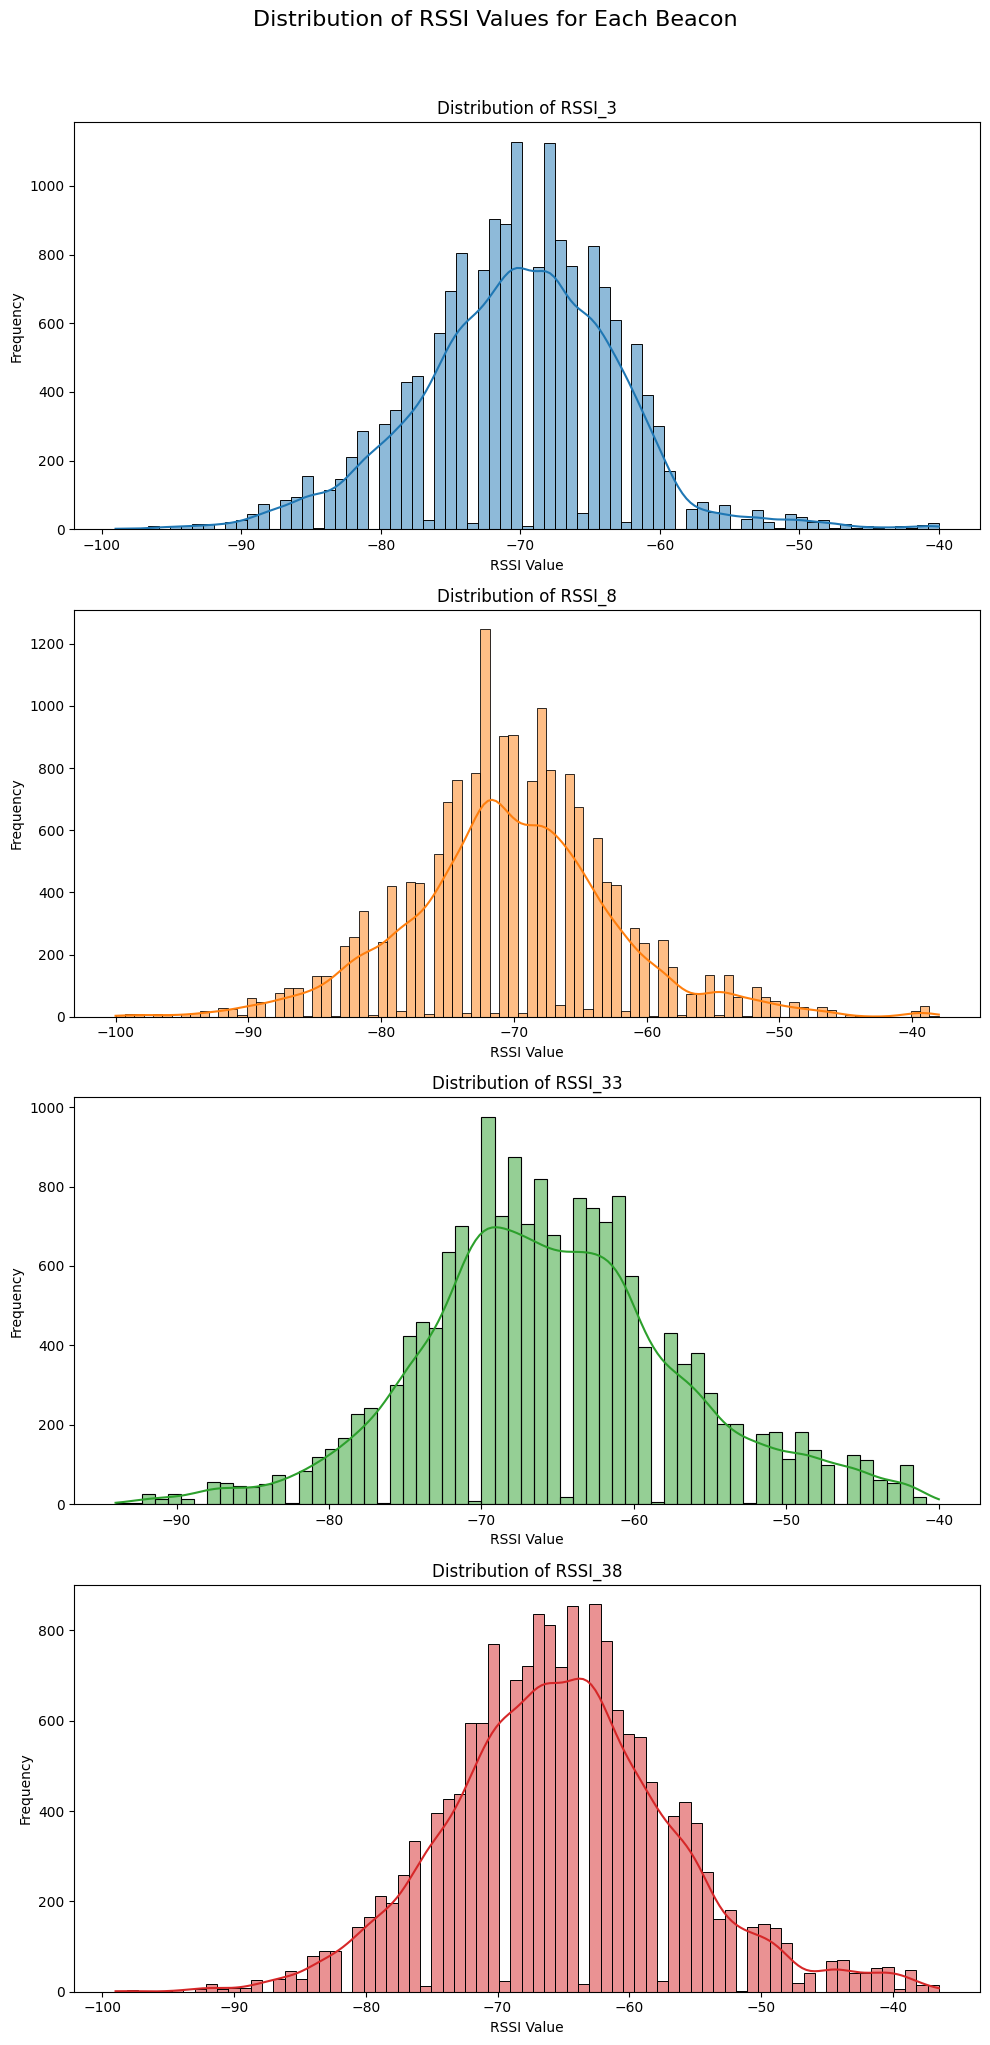

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'wide_complete' and 'beacon_cols' are available from previous steps

fig, axes = plt.subplots(len(beacon_cols), 1, figsize=(10, 5 * len(beacon_cols)))
fig.suptitle('Distribution of RSSI Values for Each Beacon', y=1.02, fontsize=16)

for i, col in enumerate(beacon_cols):
    sns.histplot(wide_complete[col], kde=True, ax=axes[i], color=f'C{i}')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel('RSSI Value')
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

In [34]:
max_rssi = wide_complete[beacon_cols].max().max()
min_rssi = wide_complete[beacon_cols].min().min()

print(f"Maximum RSSI across all beacons: {max_rssi}")
print(f"Minimum RSSI across all beacons: {min_rssi}")

Maximum RSSI across all beacons: -36.5
Minimum RSSI across all beacons: -100.0


Summary table saved as dataset_summary.png


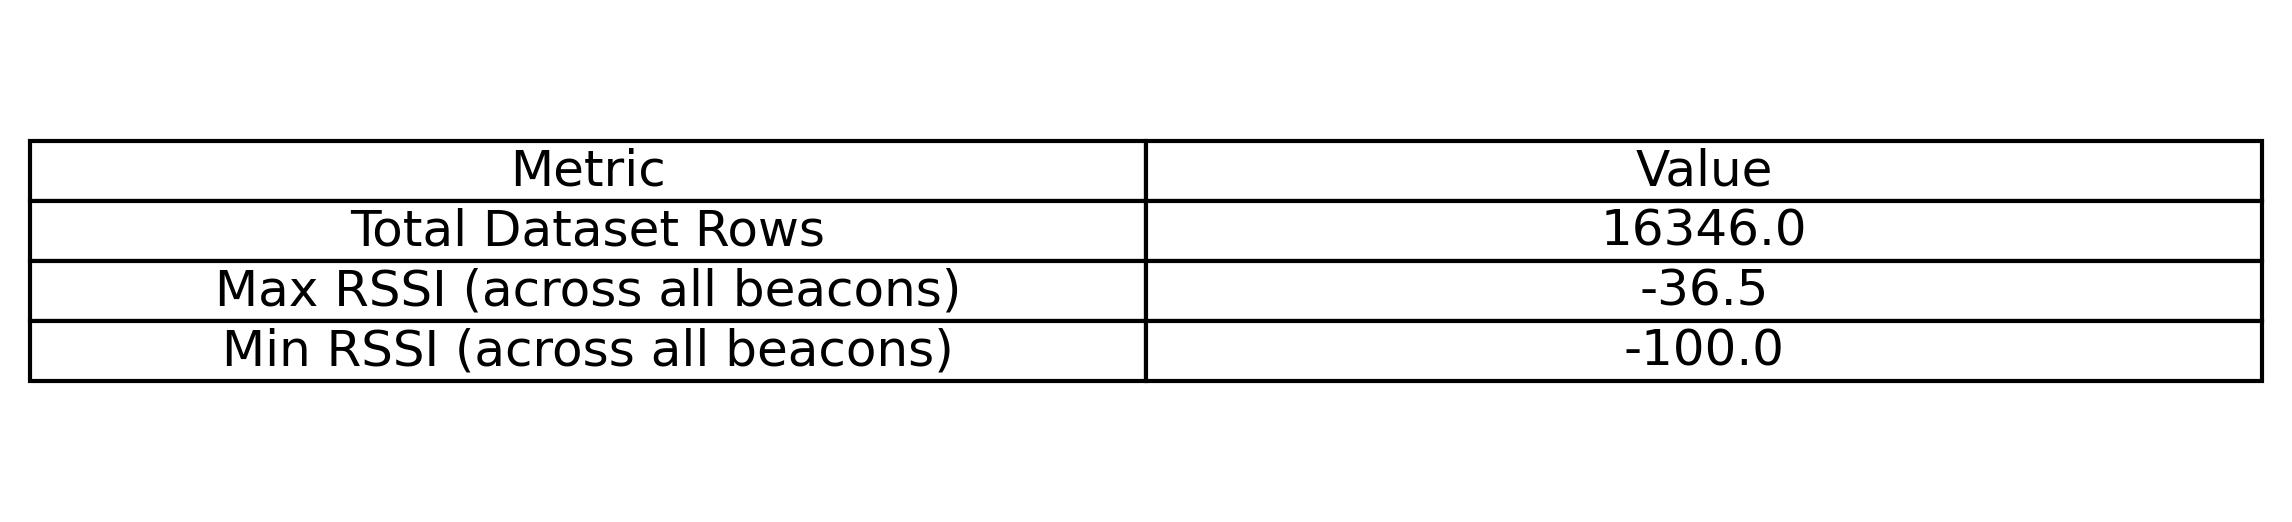

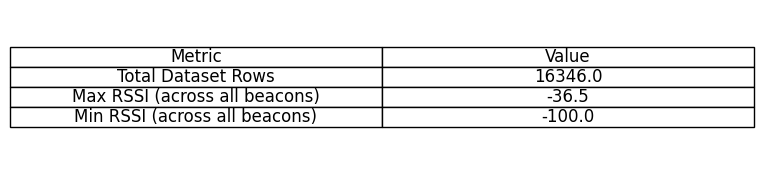

In [35]:
import matplotlib.pyplot as plt
import pandas as pd

# Create a DataFrame for the summary information
summary_data = {
    'Metric': ['Total Dataset Rows', 'Max RSSI (across all beacons)', 'Min RSSI (across all beacons)'],
    'Value': [len(wide_complete), max_rssi, min_rssi]
}
summary_df = pd.DataFrame(summary_data)

# Create a figure and an axes object
fig, ax = plt.subplots(figsize=(8, 2))  # Adjust size as needed
ax.axis('off')  # Hide the axes
ax.axis('tight') # Adjust the limits to fit the table

# Create the table and add it to the axes
table = ax.table(cellText=summary_df.values,
                 colLabels=summary_df.columns,
                 cellLoc='center',
                 loc='center')

# Adjust font size for better readability
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1.2, 1.2)

# Save the table as a PNG image
output_filename = 'dataset_summary.png'
plt.savefig(output_filename, bbox_inches='tight', dpi=300)

print(f'Summary table saved as {output_filename}')

# Display the image
from IPython.display import Image
Image(output_filename)